<a href="https://colab.research.google.com/github/krsnevam/ANN-Breakthrough/blob/team-butterworth/Another_copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


PyTorch version: 2.14.1+cu130
GPU available: True
GPU: Tesla T4


In [ ]:

!pip install -q torch torchvision opencv-python matplotlib numpy pillow tqdm
print("All libraries installed successfully!")


All libraries installed successfully!


In [ ]:
DATASET_PATH = "/content/idd20k_lite"

import os
print("Dataset folder exists:", os.path.exists(DATASET_PATH))

Dataset folder exists: False


In [ ]:
import tarfile

with tarfile.open("/content/idd-lite.tar", "r") as tar:
    tar.extractall("/content/")

DATASET_PATH = "/content/idd20k_lite"

print("Dataset restored!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/idd-lite.tar'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving idd-lite.tar to idd-lite.tar


In [ ]:
import tarfile
import os

tar_path = "/content/idd-lite.tar"

with tarfile.open(tar_path, "r:*") as tar:
    tar.extractall("/content/")

print("Extraction completed!")

for item in os.listdir("/content"):
    print(item)

/tmp/ipykernel_574/874912303.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content/")


Extraction completed!
.config
idd20k_lite
idd-lite.tar
sample_data


In [ ]:
import os

DATASET_PATH = "/content/idd20k_lite"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nMain folders:")

for folder in os.listdir(DATASET_PATH):
    print("📁", folder)

Dataset exists: True

Main folders:
📁 leftImg8bit
📁 gtFine


In [ ]:
for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

idd20k_lite/
  leftImg8bit/
    test/
    val/
    train/
  gtFine/
    val/
    train/


In [ ]:
import os
from glob import glob

train_images = glob(
    DATASET_PATH + "/leftImg8bit/train/**/*.png",
    recursive=True
)

train_labels = glob(
    DATASET_PATH + "/gtFine/train/**/*_label.png",
    recursive=True
)

print("Training images:", len(train_images))
print("Training labels:", len(train_labels))

print("\nSample images:")
for f in train_images[:5]:
    print(os.path.basename(f))

print("\nSample labels:")
for f in train_labels[:5]:
    print(os.path.basename(f))

Training images: 0
Training labels: 2806

Sample images:

Sample labels:
705452_label.png
554318_inst_label.png
888262_label.png
979223_label.png
554318_label.png


In [ ]:
from glob import glob
import os

train_images = glob(
    DATASET_PATH + "/leftImg8bit/train/**/*.jpg",
    recursive=True
)

train_labels = glob(
    DATASET_PATH + "/gtFine/train/**/*_label.png",
    recursive=True
)

print("Training images:", len(train_images))
print("Training labels:", len(train_labels))

print("\nSample images:")
for f in train_images[:5]:
    print(os.path.basename(f))

Training images: 1403
Training labels: 2806

Sample images:
597145_image.jpg
705452_image.jpg
554318_image.jpg
888262_image.jpg
979223_image.jpg


In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Get one training image
img_path = train_images[0]

# Find matching label using filename ID
image_id = os.path.basename(img_path).replace(".jpg", "")

matches = [
    f for f in train_labels
    if os.path.basename(f).replace("_label.png", "") == image_id
]

print("Image:", os.path.basename(img_path))
print("Matching labels:", len(matches))

if matches:
    mask_path = matches[0]

    img = Image.open(img_path)
    mask = Image.open(mask_path)

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Original Road Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask)
    plt.title("Ground Truth Segmentation Mask")
    plt.axis("off")

    plt.show()
else:
    print("No matching mask found. We need to check the filenames.")

Image: 597145_image.jpg
Matching labels: 0
No matching mask found. We need to check the filenames.


In [ ]:
import os

image_id = os.path.basename(train_images[0]).split("_")[0]

print("Image ID:", image_id)
print("\nMatching label candidates:")

for f in train_labels:
    if image_id in os.path.basename(f):
        print(os.path.basename(f))

Image ID: 597145

Matching label candidates:
597145_label.png
597145_inst_label.png


In [ ]:
print("\nFirst 10 image paths:")
for f in train_images[:10]:
    print(f)

print("\nFirst 10 label paths:")
for f in train_labels[:10]:
    print(f)


First 10 image paths:
/content/idd20k_lite/leftImg8bit/train/162/597145_image.jpg
/content/idd20k_lite/leftImg8bit/train/162/705452_image.jpg
/content/idd20k_lite/leftImg8bit/train/162/554318_image.jpg
/content/idd20k_lite/leftImg8bit/train/162/888262_image.jpg
/content/idd20k_lite/leftImg8bit/train/162/979223_image.jpg
/content/idd20k_lite/leftImg8bit/train/237/frame5584_image.jpg
/content/idd20k_lite/leftImg8bit/train/237/frame2459_image.jpg
/content/idd20k_lite/leftImg8bit/train/237/frame71226_image.jpg
/content/idd20k_lite/leftImg8bit/train/237/frame10612_image.jpg
/content/idd20k_lite/leftImg8bit/train/237/frame7434_image.jpg

First 10 label paths:
/content/idd20k_lite/gtFine/train/162/705452_label.png
/content/idd20k_lite/gtFine/train/162/554318_inst_label.png
/content/idd20k_lite/gtFine/train/162/888262_label.png
/content/idd20k_lite/gtFine/train/162/979223_label.png
/content/idd20k_lite/gtFine/train/162/554318_label.png
/content/idd20k_lite/gtFine/train/162/888262_inst_label.p

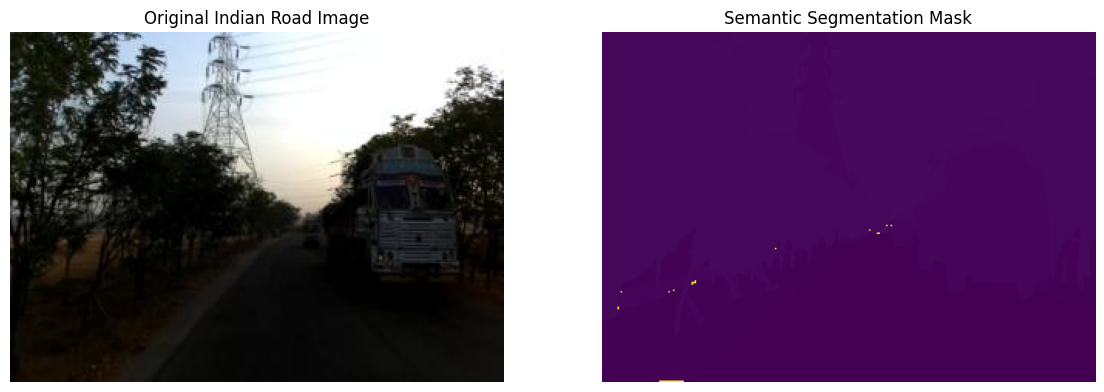

Image size: (320, 227)
Mask size: (320, 227)
Mask values: 7


In [ ]:
import os
import matplotlib.pyplot as plt
from PIL import Image

img_path = train_images[0]

image_id = os.path.basename(img_path).split("_")[0]
folder = os.path.dirname(img_path).replace(
    "leftImg8bit", "gtFine"
)

mask_path = os.path.join(folder, image_id + "_label.png")

img = Image.open(img_path)
mask = Image.open(mask_path)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Indian Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.title("Semantic Segmentation Mask")
plt.axis("off")

plt.show()

print("Image size:", img.size)
print("Mask size:", mask.size)
print("Mask values:", len(set(mask.getdata())))

In [ ]:
import numpy as np
from PIL import Image

mask_array = np.array(mask)

unique_values, counts = np.unique(
    mask_array, return_counts=True
)

print("Pixel values and counts:")

for value, count in zip(unique_values, counts):
    print(f"Class ID {value}: {count} pixels")

Pixel values and counts:
Class ID 0: 15614 pixels
Class ID 1: 7688 pixels
Class ID 3: 6732 pixels
Class ID 4: 2634 pixels
Class ID 5: 25696 pixels
Class ID 6: 14244 pixels
Class ID 255: 32 pixels


In [ ]:
print("Mask data type:", mask_array.dtype)
print("Unique class IDs:", unique_values)

Mask data type: uint8
Unique class IDs: [  0   1   3   4   5   6 255]


In [ ]:
import numpy as np

unique, counts = np.unique(mask_array, return_counts=True)

for value, count in zip(unique, counts):
    percentage = count / mask_array.size * 100
    print(f"ID {value}: {count} pixels ({percentage:.2f}%)")

ID 0: 15614 pixels (21.50%)
ID 1: 7688 pixels (10.58%)
ID 3: 6732 pixels (9.27%)
ID 4: 2634 pixels (3.63%)
ID 5: 25696 pixels (35.37%)
ID 6: 14244 pixels (19.61%)
ID 255: 32 pixels (0.04%)


In [ ]:
print("Dataset label folders:")
import os

for root, dirs, files in os.walk(DATASET_PATH + "/gtFine/train"):
    print(root, "files:", len(files))
    if root.count(os.sep) > DATASET_PATH.count(os.sep) + 2:
        dirs.clear()

Dataset label folders:
/content/idd20k_lite/gtFine/train files: 0
/content/idd20k_lite/gtFine/train/162 files: 10
/content/idd20k_lite/gtFine/train/237 files: 32
/content/idd20k_lite/gtFine/train/78 files: 6
/content/idd20k_lite/gtFine/train/457 files: 2
/content/idd20k_lite/gtFine/train/243 files: 6
/content/idd20k_lite/gtFine/train/174 files: 16
/content/idd20k_lite/gtFine/train/493 files: 2
/content/idd20k_lite/gtFine/train/547 files: 8
/content/idd20k_lite/gtFine/train/288 files: 8
/content/idd20k_lite/gtFine/train/5 files: 20
/content/idd20k_lite/gtFine/train/211 files: 2
/content/idd20k_lite/gtFine/train/142 files: 8
/content/idd20k_lite/gtFine/train/125 files: 8
/content/idd20k_lite/gtFine/train/36 files: 24
/content/idd20k_lite/gtFine/train/377 files: 72
/content/idd20k_lite/gtFine/train/577 files: 2
/content/idd20k_lite/gtFine/train/354 files: 2
/content/idd20k_lite/gtFine/train/23 files: 20
/content/idd20k_lite/gtFine/train/522 files: 2
/content/idd20k_lite/gtFine/train/133 f

In [ ]:
import numpy as np

mask_array = np.array(mask)

unique, counts = np.unique(mask_array, return_counts=True)

print("Pixel distribution:")
for value, count in zip(unique, counts):
    print(f"Class ID {value}: {count} pixels")

Pixel distribution:
Class ID 0: 15614 pixels
Class ID 1: 7688 pixels
Class ID 3: 6732 pixels
Class ID 4: 2634 pixels
Class ID 5: 25696 pixels
Class ID 6: 14244 pixels
Class ID 255: 32 pixels


In [ ]:
import os

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.endswith((".yaml", ".yml", ".json", ".txt")):
            print(os.path.join(root, file))

In [ ]:
import glob
import numpy as np
from PIL import Image
from collections import Counter

label_files = glob.glob(
    DATASET_PATH + "/gtFine/train/**/*_label.png",
    recursive=True
)

total_counts = Counter()

for path in label_files:
    mask = np.array(Image.open(path))
    values, counts = np.unique(mask, return_counts=True)
    for v, c in zip(values, counts):
        total_counts[int(v)] += int(c)

print("Training masks:", len(label_files))
print("All pixel IDs across training set:")

for class_id, count in sorted(total_counts.items()):
    print(f"ID {class_id}: {count:,} pixels")

Training masks: 2806
All pixel IDs across training set:
ID 0: 66,009,378 pixels
ID 1: 4,456,700 pixels
ID 2: 2,660,414 pixels
ID 3: 16,420,334 pixels
ID 4: 22,836,714 pixels
ID 5: 52,944,492 pixels
ID 6: 38,466,210 pixels
ID 255: 33,598 pixels


In [ ]:
import torch
import numpy as np
from PIL import Image

NUM_CLASSES = 7
IGNORE_INDEX = 255

CLASS_NAMES = [
    "Drivable",
    "Non-drivable",
    "Living things",
    "Vehicles",
    "Roadside objects",
    "Far objects",
    "Sky"
]

def process_mask(path):
    mask = np.array(Image.open(path), dtype=np.uint8)
    return torch.tensor(mask, dtype=torch.long)

print("Classes:", NUM_CLASSES)
print("Class names:", CLASS_NAMES)
print("Ignore index:", IGNORE_INDEX)
print("GPU:", torch.cuda.get_device_name(0))

Classes: 7
Class names: ['Drivable', 'Non-drivable', 'Living things', 'Vehicles', 'Roadside objects', 'Far objects', 'Sky']
Ignore index: 255
GPU: Tesla T4


In [ ]:
!pip install -q transformers==4.44.2 accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for tokenizers (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for tokenizers
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> tokenizers


In [ ]:
!pip install -q --upgrade pip
!pip install -q transformers accelerate

In [ ]:
CLASS_NAMES = [
    "Drivable",
    "Non-drivable",
    "Living things",
    "Vehicles",
    "Roadside objects",
    "Far objects",
    "Sky"
]

print("Class names restored!")

Class names restored!


In [ ]:
import torch
from transformers import SegformerForSemanticSegmentation

MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"

model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=7,
    ignore_mismatched_sizes=True,
    id2label={i: name for i, name in enumerate(CLASS_NAMES)},
    label2id={name: i for i, name in enumerate(CLASS_NAMES)}
)

model.config.semantic_loss_ignore_index = 255
model = model.to("cuda")

print("Model loaded successfully!")
print("Classes:", model.config.num_labels)
print("Device:", next(model.parameters()).device)

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

[transformers] You passed `num_labels=7` which is incompatible to the `id2label` map of length `150`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-ade-512-512
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 256, 1, 1]) vs model:torch.Size([7, 256, 1, 1])
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([7])                      

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model loaded successfully!
Classes: 7
Device: cuda:0


In [ ]:
import os, glob
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DATASET_PATH = "/content/idd20k_lite"

def get_pairs(split):
    images = glob.glob(
        f"{DATASET_PATH}/leftImg8bit/{split}/**/*.jpg",
        recursive=True
    )
    pairs = []

    for img_path in images:
        image_id = os.path.basename(img_path).split("_")[0]
        folder = os.path.dirname(img_path).replace(
            "leftImg8bit", "gtFine"
        )
        mask_path = os.path.join(folder, image_id + "_label.png")

        if os.path.exists(mask_path):
            pairs.append((img_path, mask_path))

    return pairs

train_pairs = get_pairs("train")
val_pairs = get_pairs("val")

print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))

Training pairs: 1403
Validation pairs: 204


In [ ]:
images, masks = next(iter(train_loader))

print("Image batch:", images.shape)
print("Mask batch:", masks.shape)
print("Mask class IDs:", torch.unique(masks))

NameError: name 'train_loader' is not defined

In [ ]:
import os
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class IDDDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs
        self.transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        image = self.transform(image)
        mask = mask.resize((256, 256), Image.Resampling.NEAREST)
        mask = torch.tensor(np.array(mask).copy(), dtype=torch.long)

        return image, mask

train_loader = DataLoader(
    IDDDataset(train_pairs),
    batch_size=4,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    IDDDataset(val_pairs),
    batch_size=4,
    shuffle=False,
    num_workers=2
)

print("Training loader:", len(train_loader))
print("Validation loader:", len(val_loader))

Training loader: 351
Validation loader: 51


In [ ]:
images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Class IDs:", torch.unique(masks))

Images: torch.Size([4, 3, 256, 256])
Masks: torch.Size([4, 256, 256])
Class IDs: tensor([  0,   1,   2,   3,   4,   5,   6, 255])


In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW

device = "cuda"

optimizer = AdamW(model.parameters(), lr=0.00005)

criterion = nn.CrossEntropyLoss(ignore_index=255)

EPOCHS = 10

print("Training setup ready!")

Training setup ready!


In [ ]:
from tqdm.auto import tqdm

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    progress = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for images, masks in progress:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)
        logits = torch.nn.functional.interpolate(
            outputs.logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress.set_postfix(loss=loss.item())

    print(f"Epoch {epoch+1}: Loss = {total_loss / len(train_loader):.4f}")

torch.save(model.state_dict(), "/content/idd_segformer.pth")
print("Training complete! Model saved.")


Epoch 1/10:   0%|          | 0/351 [00:00<?, ?it/s]

Epoch 1: Loss = 0.8798


Epoch 2/10:   0%|          | 0/351 [00:00<?, ?it/s]

Epoch 2: Loss = 0.5223


Epoch 3/10:   0%|          | 0/351 [00:00<?, ?it/s]

Epoch 3: Loss = 0.4334


... (13 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac7d6a24220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ac7d6a24220>    if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Traceback (most recent call last):
assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
:     can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Exception ignored in:     <function _M

Epoch 9: Loss = 0.2842


Epoch 10/10:   0%|          | 0/351 [00:00<?, ?it/s]

Epoch 10: Loss = 0.2787
Training complete! Model saved.


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

model.eval()

NUM_CLASSES = 7
confusion_matrix = torch.zeros(
    (NUM_CLASSES, NUM_CLASSES),
    dtype=torch.int64,
    device=device
)

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(pixel_values=images)

        logits = F.interpolate(
            outputs.logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        predictions = logits.argmax(dim=1)

        valid = masks != 255
        targets = masks[valid]
        preds = predictions[valid]

        indices = targets * NUM_CLASSES + preds

        confusion_matrix += torch.bincount(
            indices,
            minlength=NUM_CLASSES ** 2
        ).reshape(NUM_CLASSES, NUM_CLASSES)

# Calculate IoU
intersection = confusion_matrix.diag()
union = (
    confusion_matrix.sum(dim=0)
    + confusion_matrix.sum(dim=1)
    - intersection
)

iou = intersection.float() / union.float().clamp(min=1)
iou[union == 0] = float("nan")

class_names = [
    "Drivable",
    "Non-drivable",
    "Living things",
    "Vehicles",
    "Roadside objects",
    "Far objects",
    "Sky"
]

print("\nPER-CLASS IoU")
for name, score in zip(class_names, iou.cpu().numpy()):
    print(f"{name}: {score:.4f} ({score*100:.2f}%)")

mean_iou = torch.nanmean(iou).item()

print("\nMean IoU:", round(mean_iou, 4))
print("Mean IoU percentage:", round(mean_iou * 100, 2), "%")


PER-CLASS IoU
Drivable: 0.9223 (92.23%)
Non-drivable: 0.3586 (35.86%)
Living things: 0.3778 (37.78%)
Vehicles: 0.6970 (69.70%)
Roadside objects: 0.4478 (44.78%)
Far objects: 0.7389 (73.89%)
Sky: 0.9348 (93.48%)

Mean IoU: 0.6396
Mean IoU percentage: 63.96 %


In [ ]:
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# Give more importance to weaker classes
class_weights = torch.tensor(
    [1.0, 2.2, 2.5, 1.3, 1.5, 1.1, 1.0],
    dtype=torch.float32,
    device=device
)

criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.00001
)

best_class1_iou = 0
best_state = None

for epoch in range(3):
    model.train()
    total_loss = 0

    for images, masks in tqdm(train_loader, desc=f"Fine-tuning {epoch+1}/3"):
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(pixel_values=images)
        logits = F.interpolate(
            outputs.logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model.eval()
    cm = torch.zeros((7, 7), dtype=torch.int64, device=device)

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)

            logits = model(pixel_values=images).logits
            logits = F.interpolate(
                logits, size=masks.shape[-2:],
                mode="bilinear", align_corners=False
            )

            preds = logits.argmax(dim=1)
            valid = masks != 255

            idx = masks[valid] * 7 + preds[valid]
            cm += torch.bincount(idx, minlength=49).reshape(7, 7)

    inter = cm.diag().float()
    union = cm.sum(0) + cm.sum(1) - inter
    scores = inter / union.clamp(min=1)
    scores[union == 0] = float("nan")

    miou = torch.nanmean(scores).item()
    non_drivable_iou = scores[1].item()

    print(f"\nEpoch {epoch+1} loss: {total_loss/len(train_loader):.4f}")
    print(f"Non-drivable IoU: {non_drivable_iou*100:.2f}%")
    print(f"Mean IoU: {miou*100:.2f}%")

    # Keep the best non-drivable result
    if non_drivable_iou > best_class1_iou:
        best_class1_iou = non_drivable_iou
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }

if best_state is not None:
    model.load_state_dict(best_state)
    model.to(device)
    torch.save(model.state_dict(), "/content/idd_segformer_improved.pth")
    print("\nBest fine-tuned model saved!")

Fine-tuning 1/3:   0%|          | 0/351 [00:00<?, ?it/s]


Epoch 1 loss: 0.3206
Non-drivable IoU: 39.78%
Mean IoU: 64.56%


Fine-tuning 2/3:   0%|          | 0/351 [00:00<?, ?it/s]


Epoch 2 loss: 0.3150
Non-drivable IoU: 40.52%
Mean IoU: 64.70%


Fine-tuning 3/3:   0%|          | 0/351 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac7d6a24220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ac7d6a24220>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 3 loss: 0.3099
Non-drivable IoU: 39.95%
Mean IoU: 64.39%

Best fine-tuned model saved!


In [ ]:
model.load_state_dict(
    torch.load(
        "/content/idd_segformer_improved.pth",
        map_location=device
    )
)
model.to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.000003
)

print("Best checkpoint restored. Ready for final fine-tuning.")

Best checkpoint restored. Ready for final fine-tuning.


In [ ]:
for epoch in range(2):
    model.train()
    total_loss = 0

    for images, masks in tqdm(train_loader):
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        logits = model(pixel_values=images).logits

        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Final epoch {epoch+1} loss: {total_loss/len(train_loader):.4f}")

  0%|          | 0/351 [00:00<?, ?it/s]

Final epoch 1 loss: 0.3103


  0%|          | 0/351 [00:00<?, ?it/s]

Final epoch 2 loss: 0.3092


In [ ]:
torch.save(model.state_dict(), "/content/idd_segformer_final.pth")
print("Final model saved successfully!")

Final model saved successfully!


In [ ]:
import torch
import torch.nn.functional as F

model.eval()

cm = torch.zeros((7, 7), dtype=torch.int64, device="cuda")

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to("cuda")
        masks = masks.to("cuda")

        logits = model(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=masks.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        preds = logits.argmax(dim=1)
        valid = masks != 255

        ids = masks[valid] * 7 + preds[valid]
        cm += torch.bincount(ids, minlength=49).reshape(7, 7)

intersection = cm.diag().float()
union = cm.sum(0) + cm.sum(1) - intersection
iou = intersection / union.clamp(min=1)

names = [
    "Drivable", "Non-drivable", "Living things",
    "Vehicles", "Roadside objects", "Far objects", "Sky"
]

for name, score in zip(names, iou.cpu().tolist()):
    print(f"{name}: {score*100:.2f}%")

print("\nMean IoU:", round(iou.mean().item()*100, 2), "%")
print("Non-drivable IoU:", round(iou[1].item()*100, 2), "%")

Drivable: 92.32%
Non-drivable: 40.33%
Living things: 37.87%
Vehicles: 69.38%
Roadside objects: 46.10%
Far objects: 73.60%
Sky: 93.49%

Mean IoU: 64.73 %
Non-drivable IoU: 40.33 %


In [ ]:
torch.save(model.state_dict(), "/content/idd_segformer_final.pth")

print("Final model saved!")

Final model saved!


In [ ]:
torch.save(model.state_dict(), "/content/idd_segformer_baseline.pth")
print("Baseline model backed up!")

Baseline model backed up!


In [ ]:
import torch
import transformers
import tokenizers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Tokenizers:", tokenizers.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Transformers: 5.22.1
Tokenizers: 0.23.3
GPU: Tesla T4


In [ ]:
import torch
from transformers import SegformerForSemanticSegmentation

MODEL_NAME = "nvidia/segformer-b0-finetuned-ade-512-512"

model = SegformerForSemanticSegmentation.from_pretrained(
    MODEL_NAME,
    num_labels=7,
    ignore_mismatched_sizes=True,
    id2label={i: name for i, name in enumerate(CLASS_NAMES)},
    label2id={name: i for i, name in enumerate(CLASS_NAMES)}
)

model.config.semantic_loss_ignore_index = 255
model = model.to("cuda")

print("Model loaded successfully!")
print("Classes:", model.config.num_labels)
print("Device:", next(model.parameters()).device)

NameError: name 'CLASS_NAMES' is not defined

In [ ]:

import torch
import torchvision
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("All imports successful!")
print("GPU:", torch.cuda.get_device_name(0))


All imports successful!
GPU: Tesla T4


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving idd-lite.tar to idd-lite.tar


In [ ]:
import tarfile
import os

tar_path = "/content/idd-lite.tar"

with tarfile.open(tar_path, "r") as tar:
    tar.extractall("/content/")

DATASET_PATH = "/content/idd20k_lite"

print("Dataset extracted!")
print("Folders:", os.listdir(DATASET_PATH))

/tmp/ipykernel_323/1978974101.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("/content/")


Dataset extracted!
Folders: ['leftImg8bit', 'gtFine']


In [ ]:
import os

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, '').count(os.sep)
    if level <= 3:
        print('  ' * level + os.path.basename(root) + '/')
        for f in files[:3]:
            print('  ' * (level + 1) + f)

idd20k_lite/
  leftImg8bit/
    test/
      83/
        501097_image.jpg
        478467_image.jpg
        477950_image.jpg
      304/
        frame0864_image.jpg
      14/
        983201_image.jpg
        964050_image.jpg
        829567_image.jpg
      97/
        066445_image.jpg
        300873_image.jpg
        456933_image.jpg
      8/
        505327_image.jpg
        493615_image.jpg
        004475_image.jpg
      159/
        627463_image.jpg
      92/
        941649_image.jpg
        824026_image.jpg
        635434_image.jpg
      229/
        frame5088_image.jpg
      576/
        0000925_image.jpg
      281/
        frame2194_image.jpg
        frame1396_image.jpg
      566/
        frame2399_image.jpg
        frame0749_image.jpg
      546/
        0008931_image.jpg
        0023390_image.jpg
        0001406_image.jpg
      19/
        439348_image.jpg
        894649_image.jpg
        171279_image.jpg
      54/
        383874_image.jpg
      22/
        133981_image.jpg
        3

In [ ]:
import random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF

class IDDAugmentedDataset(Dataset):
    def __init__(self, pairs, is_train=True):
        self.pairs = pairs
        self.is_train = is_train

        # Standard image normalization
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # 1. Resize both to 256x256
        image = image.resize((256, 256), Image.Resampling.BILINEAR)
        mask = mask.resize((256, 256), Image.Resampling.NEAREST)

        # 2. Apply synchronized transformations for training
        if self.is_train:
            # Random horizontal flip
            if random.random() > 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            # Random rotation
            if random.random() > 0.5:
                angle = random.randint(-10, 10)
                image = TF.rotate(image, angle, interpolation=transforms.InterpolationMode.BILINEAR)
                mask = TF.rotate(mask, angle, interpolation=transforms.InterpolationMode.NEAREST, fill=255)

            # Color jitter (only apply to image, not mask!)
            if random.random() > 0.5:
                color_jitter = transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)
                image = color_jitter(image)

        # Convert image to tensor and normalize
        image = TF.to_tensor(image)
        image = self.normalize(image)

        # Convert mask to long tensor
        mask = torch.tensor(np.array(mask).copy(), dtype=torch.long)

        return image, mask

# Create train and validation pairs from dataset
import glob
import os

def get_pairs(split):
    images = glob.glob(f"{DATASET_PATH}/leftImg8bit/{split}/**/*.jpg", recursive=True)
    pairs = []
    for img_path in images:
        image_id = os.path.basename(img_path).split("_")[0]
        folder = os.path.dirname(img_path).replace("leftImg8bit", "gtFine")
        mask_path = os.path.join(folder, image_id + "_label.png")
        if os.path.exists(mask_path):
            pairs.append((img_path, mask_path))
    return pairs

train_pairs = get_pairs("train")
val_pairs = get_pairs("val")

print(f"Loaded {len(train_pairs)} train pairs and {len(val_pairs)} val pairs.")


In [ ]:
# Initialize DataLoaders
train_dataset = IDDAugmentedDataset(train_pairs, is_train=True)
val_dataset = IDDAugmentedDataset(val_pairs, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")
